# Synthetic Hotel Data Generation — 1,685 Unique Hotels

This notebook takes the cleaned **1,685 unique hotel dataset** and:

1. Loads and inspects the data
2. Checks missing values and data types
3. Separates identifiers and derived fields from modeling fields
4. Cleans categorical, numeric, and binary amenity columns
5. Trains a **CTGAN** model using SDV
6. Generates **3,000 synthetic hotels**
7. Validates categorical and binary amenity values
8. Recalculates `amenity_count`, `log_price`, `PCA1`, and `PCA2`
9. Checks exact and near-duplicate synthetic hotels
10. Adds `data_type = Real/Synthetic`
11. Saves real, synthetic, and combined CSV files
12. Compares real vs synthetic distributions using statistics and plots

> **Important:** Synthetic hotels are not real hotels. Keep `data_type` in the final dataset so they can always be distinguished.

In [ ]:
# ============================================================
# CELL 1 — Install required packages
# ============================================================

!pip -q install sdv scikit-learn pandas numpy matplotlib seaborn scipy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 215.6/215.6 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.0/140.0 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.0/16.0 MB 29.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.7/52.7 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.5/75.5 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 259.9/259.9 kB 10.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 29.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 kB 3.1 MB/s eta 0:00:00


In [ ]:
# ============================================================
# CELL 2 — Imports and configuration
# ============================================================

import os
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ks_2samp, chi2_contingency
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import pairwise_distances

from sdv.metadata import Metadata
from sdv.single_table import CTGANSynthesizer

warnings.filterwarnings("ignore")

RANDOM_SEED = 42
N_SYNTHETIC = 3000

np.random.seed(RANDOM_SEED)

print("Libraries loaded successfully.")

Libraries loaded successfully.


## 1. Upload and load the 1,685-hotel dataset

In Google Colab, upload:

`all_india_1685_unique_hotels.csv`

If the file is already present in `/content`, the upload cell can be skipped.

In [ ]:
# ============================================================
# CELL 3 — Upload CSV
# ============================================================

from google.colab import files

uploaded = files.upload()

FILE_NAME = "all_india_1685_unique_hotels.csv"

if FILE_NAME not in uploaded and not os.path.exists(FILE_NAME):
    print("Available uploaded files:", list(uploaded.keys()))
    raise FileNotFoundError(
        f"{FILE_NAME} was not found. Upload the file with this exact name."
    )

print("Using:", FILE_NAME)

Saving all_india_1685_unique_hotels.csv to all_india_1685_unique_hotels (1).csv
Using: all_india_1685_unique_hotels.csv


In [ ]:
# ============================================================
# CELL 4 — Load dataset
# ============================================================

df = pd.read_csv(FILE_NAME)

print("Shape:", df.shape)
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

Shape: (1685, 30)


,hotel_id,hotel_name,location,hotel_category,price,log_price,customer_rating,review_count,amenities,latitude,...,amenity_airport_shuttle,amenity_accessible,amenity_kitchen_in_some_rooms,amenity_smoke_free_property,amenity_breakfast_($),amenity_bar,amenity_parking,PCA1,PCA2,success
0,ChUImcGzjY7CnO55GgkvbS8wOV80NDYQAQ,"The Oberoi Grand, Kolkata",Kolkata,5-star hotel,NaN,NaN,4.4,30193.0,accessible | air conditioning | airport shuttl...,NaN,...,1,1,1,0,0,1,1,3.228929,0.958883,1
1,ChYI-PvamN_4iPVCGgovbS8waF9jNzY1EAE,The Accord Metropolitan,Chennai,5-star hotel,7961.0,8.982436,4.4,12467.0,accessible | air conditioning | bar | business...,13.046032,...,0,1,1,0,0,1,1,2.715822,0.814054,1
2,ChYI29ajs42Eye9DGgovbS8wcGQ5OHB5EAE,The Westin Chennai Velachery,Chennai,5-star hotel,15306.0,9.636066,4.4,12767.0,accessible | air conditioning | airport shuttl...,12.989379,...,1,1,1,1,0,1,1,2.450263,-1.106271,1
3,ChYI2LPGxbrC7a9cGgovbS8wd2ZnMjc3EAE,"ITC Grand Central, a Luxury Collection Hotel, ...",Mumbai,5-star hotel,33024.0,10.405020,4.7,24017.0,accessible | air conditioning | bar | business...,NaN,...,0,1,0,0,0,1,1,2.137971,-0.936876,1
4,ChYI2qaDle7V6PssGgovbS8wajI0ZmMyEAE,Diggi Palace – A Heritage Hotel,Jaipur,4-star hotel,6987.0,8.851950,4.4,5193.0,accessible | air conditioning | bar | free bre...,26.909902,...,0,1,0,0,0,1,1,2.555395,0.110524,1



Column names:
['hotel_id', 'hotel_name', 'location', 'hotel_category', 'price', 'log_price', 'customer_rating', 'review_count', 'amenities', 'latitude', 'longitude', 'amenity_count', 'amenity_air_conditioning', 'amenity_room_service', 'amenity_full_service_laundry', 'amenity_free_wi_fi', 'amenity_kid_friendly', 'amenity_restaurant', 'amenity_free_breakfast', 'amenity_free_parking', 'amenity_airport_shuttle', 'amenity_accessible', 'amenity_kitchen_in_some_rooms', 'amenity_smoke_free_property', 'amenity_breakfast_($)', 'amenity_bar', 'amenity_parking', 'PCA1', 'PCA2', 'success']


In [ ]:
# ============================================================
# CELL 5 — Basic inspection
# ============================================================

print("Rows:", len(df))
print("Columns:", len(df.columns))
print("Duplicate rows:", df.duplicated().sum())

print("\nData types:")
display(df.dtypes.to_frame("dtype"))

print("\nMissing values:")
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).sort_values("missing_count", ascending=False)

display(missing[missing["missing_count"] > 0])

Rows: 1685
Columns: 30
Duplicate rows: 0

Data types:


,dtype
hotel_id,object
hotel_name,object
location,object
hotel_category,object
price,float64
log_price,float64
customer_rating,float64
review_count,float64
amenities,object
latitude,float64



Missing values:


,missing_count,missing_percent
longitude,1334,79.17
latitude,1334,79.17
amenities,255,15.13
price,190,11.28
log_price,190,11.28
review_count,21,1.25
customer_rating,21,1.25


## 2. Identify column groups

The original hotel file contains:

- identifiers: `hotel_id`, `hotel_name`
- raw text: `amenities`
- hotel characteristics: city/location/category/price/rating/reviews
- amenity binary indicators
- derived fields: `log_price`, `amenity_count`, `PCA1`, `PCA2`
- target: `success`

We will **not train CTGAN on identifiers or derived fields**. These will be generated/recalculated afterward.

In [ ]:
# ============================================================
# CELL 6 — Define columns
# ============================================================

ID_COLS = [
    "hotel_id",
    "hotel_name"
]

RAW_TEXT_COLS = [
    "amenities"
]

DERIVED_COLS = [
    "log_price",
    "amenity_count",
    "PCA1",
    "PCA2"
]

AMENITY_COLS = [
    c for c in df.columns
    if c.startswith("amenity_")
]

TARGET_COL = "success"

CORE_COLS = [
    "location",
    "hotel_category",
    "price",
    "customer_rating",
    "review_count",
    "latitude",
    "longitude"
]

MODEL_COLS = CORE_COLS + AMENITY_COLS + [TARGET_COL]

print("Amenity columns:")
print(AMENITY_COLS)

print("\nModel columns:")
print(MODEL_COLS)

Amenity columns:
['amenity_count', 'amenity_air_conditioning', 'amenity_room_service', 'amenity_full_service_laundry', 'amenity_free_wi_fi', 'amenity_kid_friendly', 'amenity_restaurant', 'amenity_free_breakfast', 'amenity_free_parking', 'amenity_airport_shuttle', 'amenity_accessible', 'amenity_kitchen_in_some_rooms', 'amenity_smoke_free_property', 'amenity_breakfast_($)', 'amenity_bar', 'amenity_parking']

Model columns:
['location', 'hotel_category', 'price', 'customer_rating', 'review_count', 'latitude', 'longitude', 'amenity_count', 'amenity_air_conditioning', 'amenity_room_service', 'amenity_full_service_laundry', 'amenity_free_wi_fi', 'amenity_kid_friendly', 'amenity_restaurant', 'amenity_free_breakfast', 'amenity_free_parking', 'amenity_airport_shuttle', 'amenity_accessible', 'amenity_kitchen_in_some_rooms', 'amenity_smoke_free_property', 'amenity_breakfast_($)', 'amenity_bar', 'amenity_parking', 'success']


In [ ]:
# ============================================================
# CELL 7 — Verify expected columns
# ============================================================

missing_expected = [
    c for c in MODEL_COLS
    if c not in df.columns
]

if missing_expected:
    raise ValueError(
        "These expected columns are missing from the dataset: "
        + str(missing_expected)
    )

print("All required modeling columns are present.")

All required modeling columns are present.


## 3. Clean the CTGAN input

CTGAN works best when:

- categorical columns are strings
- numeric columns are numeric
- binary amenity columns contain only 0/1
- missing values are handled consistently

We use the **median** for numeric missing values and the **mode** for categorical missing values.

In [ ]:
# ============================================================
# CELL 8 — Clean categorical and numeric columns
# ============================================================

model_df = df[MODEL_COLS].copy()

# Categorical columns
CATEGORICAL_COLS = [
    "location",
    "hotel_category"
]

# Convert categorical columns to strings
for col in CATEGORICAL_COLS:
    model_df[col] = model_df[col].astype("string")
    mode_value = model_df[col].mode(dropna=True)
    fill_value = mode_value.iloc[0] if len(mode_value) else "Unknown"
    model_df[col] = model_df[col].fillna(fill_value).astype(str)

# Numeric columns
NUMERIC_COLS = [
    "price",
    "customer_rating",
    "review_count",
    "latitude",
    "longitude"
]

for col in NUMERIC_COLS:
    model_df[col] = pd.to_numeric(model_df[col], errors="coerce")
    model_df[col] = model_df[col].replace([np.inf, -np.inf], np.nan)

    median_value = model_df[col].median()
    model_df[col] = model_df[col].fillna(median_value)

# Amenity and success columns
BINARY_COLS = AMENITY_COLS + [TARGET_COL]

for col in BINARY_COLS:
    model_df[col] = pd.to_numeric(model_df[col], errors="coerce")
    model_df[col] = model_df[col].fillna(0)
    model_df[col] = (model_df[col] >= 0.5).astype(int)

print("Remaining missing values:", int(model_df.isna().sum().sum()))
display(model_df.head())

Remaining missing values: 0


,location,hotel_category,price,customer_rating,review_count,latitude,longitude,amenity_count,amenity_air_conditioning,amenity_room_service,...,amenity_free_breakfast,amenity_free_parking,amenity_airport_shuttle,amenity_accessible,amenity_kitchen_in_some_rooms,amenity_smoke_free_property,amenity_breakfast_($),amenity_bar,amenity_parking,success
0,Kolkata,5-star hotel,2475.0,4.4,30193.0,17.685204,80.244988,1,1,1,...,1,1,1,1,1,0,0,1,1,1
1,Chennai,5-star hotel,7961.0,4.4,12467.0,13.046032,80.242575,1,1,1,...,1,1,0,1,1,0,0,1,1,1
2,Chennai,5-star hotel,15306.0,4.4,12767.0,12.989379,80.220885,1,1,1,...,0,1,1,1,1,1,0,1,1,1
3,Mumbai,5-star hotel,33024.0,4.7,24017.0,17.685204,80.244988,1,1,1,...,0,1,0,1,0,0,0,1,1,1
4,Jaipur,4-star hotel,6987.0,4.4,5193.0,26.909902,75.812471,1,1,1,...,1,1,0,1,0,0,0,1,1,1


In [ ]:
# ============================================================
# CELL 9 — Inspect distributions before synthesis
# ============================================================

print("Categorical distributions:")
for col in CATEGORICAL_COLS:
    print(f"\n{col}")
    display(model_df[col].value_counts(dropna=False).head(20))

print("\nBinary column unique values:")
for col in BINARY_COLS:
    print(col, sorted(model_df[col].unique().tolist()))

print("\nNumeric summary:")
display(model_df[NUMERIC_COLS].describe().T)

Categorical distributions:

location


,count
location,
Goa,169
Hyderabad,168
Chennai,166
Visakhapatnam,166
Delhi,163
Kolkata,160
Mumbai,156
Kochi,152
Bengaluru,150



hotel_category


,count
hotel_category,
Unknown,627
3-star hotel,614
4-star hotel,167
2-star hotel,137
5-star hotel,116
1-star hotel,24



Binary column unique values:
amenity_count [0, 1]
amenity_air_conditioning [0, 1]
amenity_room_service [0, 1]
amenity_full_service_laundry [0, 1]
amenity_free_wi_fi [0, 1]
amenity_kid_friendly [0, 1]
amenity_restaurant [0, 1]
amenity_free_breakfast [0, 1]
amenity_free_parking [0, 1]
amenity_airport_shuttle [0, 1]
amenity_accessible [0, 1]
amenity_kitchen_in_some_rooms [0, 1]
amenity_smoke_free_property [0, 1]
amenity_breakfast_($) [0, 1]
amenity_bar [0, 1]
amenity_parking [0, 1]
success [0, 1]

Numeric summary:


,count,mean,std,min,25%,50%,75%,max
price,1685.0,3568.259347,4152.882911,392.000000,1627.000000,2475.000000,3779.000000,61327.000000
customer_rating,1685.0,4.133234,0.514790,1.000000,3.900000,4.200000,4.500000,5.000000
review_count,1685.0,1939.631751,4530.216375,1.000000,156.000000,572.500000,1622.000000,88864.000000
latitude,1685.0,17.738080,2.599317,12.875598,17.685204,17.685204,17.685204,26.922670
longitude,1685.0,80.173439,1.266181,75.776856,80.244988,80.244988,80.244988,83.390912


## 4. Train CTGAN

The model learns relationships between:

- location
- hotel category
- price
- rating
- review count
- coordinates
- individual amenities
- success

The raw `amenities` text, hotel IDs/names, and derived PCA/log/count columns are excluded.

`epochs=300` is a reasonable starting point for 1,685 rows. If Colab is slow, reduce it to 100–200; for a final run, 300–500 can be tested.

In [ ]:
# ============================================================
# CELL 10 — Create SDV metadata
# ============================================================

metadata = Metadata.detect_from_dataframe(
    data=model_df
)

print(metadata)

{
    "tables": {
        "table": {
            "columns": {
                "location": {
                    "sdtype": "categorical"
                },
                "hotel_category": {
                    "sdtype": "categorical"
                },
                "price": {
                    "sdtype": "numerical"
                },
                "customer_rating": {
                    "sdtype": "numerical"
                },
                "review_count": {
                    "sdtype": "numerical"
                },
                "latitude": {
                    "pii": true,
                    "sdtype": "latitude"
                },
                "longitude": {
                    "pii": true,
                    "sdtype": "longitude"
                },
                "amenity_count": {
                    "sdtype": "categorical"
                },
                "amenity_air_conditioning": {
                    "sdtype": "categorical"
                },
          

In [ ]:
# ============================================================
# CELL 11 — Train CTGAN
# ============================================================

synthesizer = CTGANSynthesizer(
    metadata,
    epochs=300,
    batch_size=500,
    verbose=True
)

print("Training CTGAN...")
synthesizer.fit(model_df)

print("CTGAN training completed.")

Training CTGAN...


Gen. (-01.94) | Discrim. (+00.08): 100%|██████████| 300/300 [01:32<00:00,  3.26it/s]

CTGAN training completed.


## 5. Generate 3,000 synthetic hotels

In [ ]:
# ============================================================
# CELL 12 — Generate synthetic records
# ============================================================

synthetic = synthesizer.sample(
    num_rows=N_SYNTHETIC
)

print("Synthetic shape:", synthetic.shape)
display(synthetic.head())

Synthetic shape: (3000, 24)


,location,hotel_category,price,customer_rating,review_count,latitude,longitude,amenity_count,amenity_air_conditioning,amenity_room_service,...,amenity_free_breakfast,amenity_free_parking,amenity_airport_shuttle,amenity_accessible,amenity_kitchen_in_some_rooms,amenity_smoke_free_property,amenity_breakfast_($),amenity_bar,amenity_parking,success
0,Kolkata,Unknown,2514.0,5.000000,749.9,69.798560,151.030762,1,1,1,...,0,1,0,1,1,0,1,0,1,1
1,Coimbatore,4-star hotel,5260.0,4.901378,17489.0,31.840416,64.788199,1,1,1,...,1,1,1,1,0,1,0,1,1,1
2,Chennai,2-star hotel,7370.0,4.643495,8251.7,-44.207513,173.881295,1,1,1,...,0,0,0,1,0,1,0,0,1,0
3,Chennai,3-star hotel,4588.0,4.907927,22115.2,-14.934330,-109.519918,1,1,1,...,1,1,1,1,1,1,0,1,1,1
4,Kolkata,3-star hotel,2044.0,4.652781,1.0,-39.158903,153.494967,1,1,1,...,0,1,0,0,0,0,0,0,1,1


In [ ]:
# ============================================================
# CELL 13 — Validate synthetic values
# ============================================================

print("Synthetic missing values:")
display(synthetic.isna().sum().sort_values(ascending=False).head(20))

print("\nBinary column validation:")

for col in BINARY_COLS:
    values = sorted(pd.Series(synthetic[col]).dropna().unique().tolist())
    print(f"{col}: {values}")

print("\nCategorical examples:")
for col in CATEGORICAL_COLS:
    print(f"\n{col}:")
    print(synthetic[col].value_counts().head(15))

Synthetic missing values:


,0
location,0
hotel_category,0
price,0
customer_rating,0
review_count,0
latitude,0
longitude,0
amenity_count,0
amenity_air_conditioning,0
amenity_room_service,0



Binary column validation:
amenity_count: [0, 1]
amenity_air_conditioning: [0, 1]
amenity_room_service: [0, 1]
amenity_full_service_laundry: [0, 1]
amenity_free_wi_fi: [0, 1]
amenity_kid_friendly: [0, 1]
amenity_restaurant: [0, 1]
amenity_free_breakfast: [0, 1]
amenity_free_parking: [0, 1]
amenity_airport_shuttle: [0, 1]
amenity_accessible: [0, 1]
amenity_kitchen_in_some_rooms: [0, 1]
amenity_smoke_free_property: [0, 1]
amenity_breakfast_($): [0, 1]
amenity_bar: [0, 1]
amenity_parking: [0, 1]
success: [0, 1]

Categorical examples:

location:
location
Chennai          392
Mumbai           392
Delhi            332
Goa              300
Kolkata          288
Kochi            254
Bengaluru        209
Visakhapatnam    208
Hyderabad        194
Jaipur           165
Coimbatore       145
Pune             121
Name: count, dtype: int64

hotel_category:
hotel_category
3-star hotel    1245
Unknown         1019
2-star hotel     295
4-star hotel     225
5-star hotel     173
1-star hotel      43
Name: c

### Force binary amenity columns and success to valid 0/1 values

CTGAN can occasionally produce numeric values for columns that represent binary indicators. We explicitly convert them back to 0/1.

In [ ]:
# ============================================================
# CELL 14 — Enforce valid binary fields
# ============================================================

for col in BINARY_COLS:
    synthetic[col] = pd.to_numeric(synthetic[col], errors="coerce").fillna(0)
    synthetic[col] = (synthetic[col] >= 0.5).astype(int)

# Make sure categorical columns are strings
for col in CATEGORICAL_COLS:
    synthetic[col] = synthetic[col].astype(str)

# Make sure numerical columns are numeric
for col in NUMERIC_COLS:
    synthetic[col] = pd.to_numeric(synthetic[col], errors="coerce")

print("Binary validation after correction:")
for col in BINARY_COLS:
    print(col, sorted(synthetic[col].unique().tolist()))

Binary validation after correction:
amenity_count [0, 1]
amenity_air_conditioning [0, 1]
amenity_room_service [0, 1]
amenity_full_service_laundry [0, 1]
amenity_free_wi_fi [0, 1]
amenity_kid_friendly [0, 1]
amenity_restaurant [0, 1]
amenity_free_breakfast [0, 1]
amenity_free_parking [0, 1]
amenity_airport_shuttle [0, 1]
amenity_accessible [0, 1]
amenity_kitchen_in_some_rooms [0, 1]
amenity_smoke_free_property [0, 1]
amenity_breakfast_($) [0, 1]
amenity_bar [0, 1]
amenity_parking [0, 1]
success [0, 1]


## 6. Basic plausibility cleaning

Synthetic numerical values are clipped to the observed real-data ranges.

This prevents impossible values such as a negative price or a rating above the observed maximum.

In [ ]:
# ============================================================
# CELL 15 — Clip numerical values to real-data ranges
# ============================================================

for col in NUMERIC_COLS:
    real_min = model_df[col].min()
    real_max = model_df[col].max()

    synthetic[col] = synthetic[col].clip(
        lower=real_min,
        upper=real_max
    )

# Rating is conventionally 0–5 in this dataset
synthetic["customer_rating"] = synthetic["customer_rating"].clip(0, 5)

# Price should not be negative
synthetic["price"] = synthetic["price"].clip(lower=0)

# Review count should not be negative
synthetic["review_count"] = synthetic["review_count"].clip(lower=0)

print("Plausibility cleaning completed.")
display(synthetic[NUMERIC_COLS].describe().T)

Plausibility cleaning completed.


,count,mean,std,min,25%,50%,75%,max
price,3000.0,4282.245000,5436.801297,392.000000,1679.750000,2717.500000,5189.000000,61327.000000
customer_rating,3000.0,4.628359,0.517690,1.598597,4.437681,4.852610,5.000000,5.000000
review_count,3000.0,2350.208233,5289.923453,1.000000,122.200000,804.200000,1576.275000,59227.500000
latitude,3000.0,18.392650,6.655032,12.875598,12.875598,12.875598,26.922670,26.922670
longitude,3000.0,77.919568,3.387914,75.776856,75.776856,75.776856,83.390912,83.390912


## 7. Recalculate derived fields

We do **not** let CTGAN invent:

- `amenity_count`
- `log_price`
- `PCA1`
- `PCA2`

Instead, we calculate them from the generated hotel attributes.

This keeps the derived fields mathematically consistent with the synthetic amenities and price.

In [ ]:
# ============================================================
# CELL 16 — Recalculate amenity_count and log_price
# ============================================================

synthetic["amenity_count"] = synthetic[AMENITY_COLS].sum(axis=1).astype(int)

synthetic["log_price"] = np.log1p(
    synthetic["price"]
)

print("Derived fields recalculated.")
display(
    synthetic[
        ["price", "log_price", "amenity_count", "customer_rating", "success"]
    ].head()
)

Derived fields recalculated.


,price,log_price,amenity_count,customer_rating,success
0,2514.0,7.830028,10,5.000000,1
1,5260.0,8.568076,14,4.901378,1
2,7370.0,8.905309,8,4.643495,0
3,4588.0,8.431417,15,4.907927,1
4,2044.0,7.623153,9,4.652781,1


In [ ]:
# ============================================================
# CELL 17 — Recalculate PCA1 and PCA2
# ============================================================

# PCA is based only on the amenity binary variables.
scaler = StandardScaler()

real_amenity_scaled = scaler.fit_transform(
    model_df[AMENITY_COLS]
)

pca = PCA(
    n_components=2,
    random_state=RANDOM_SEED
)

real_pca = pca.fit_transform(real_amenity_scaled)

synthetic_amenity_scaled = scaler.transform(
    synthetic[AMENITY_COLS]
)

synthetic_pca = pca.transform(
    synthetic_amenity_scaled
)

# The original dataset used PCA1/PCA2, so recreate these columns.
synthetic["PCA1"] = synthetic_pca[:, 0]
synthetic["PCA2"] = synthetic_pca[:, 1]

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total explained variance:", pca.explained_variance_ratio_.sum())

display(synthetic[["PCA1", "PCA2"]].head())

Explained variance ratio: [0.37502351 0.11680115]
Total explained variance: 0.4918246606718116


,PCA1,PCA2
0,9.257337,1.006028
1,15.335235,2.686015
2,6.749128,1.127498
3,16.436407,3.663717
4,8.550169,1.747109


## 8. Generate unique fictional hotel names

The synthetic hotels receive **unique fictional names**.

Rules:
- No `Synthetic Hotel` wording
- No numbers in the hotel name
- No repeated names
- Names use fictional name components plus the generated hotel's location
- Existing real hotel names are excluded from exact-name reuse
- The technical `hotel_id` remains separate from the displayed hotel name


In [ ]:
# ============================================================
# CELL 18 — Generate unique fictional hotel names
# ============================================================


import itertools
import re
import numpy as np
name_words_1 = [
    "Aurelia", "Velora", "Seren", "Arden", "Elara", "Novara",
    "Solara", "Avira", "Rivana", "Calista", "Alora", "Elaris",
    "Lumera", "Orlena", "Zevora", "Nivara", "Celestia", "Veridia",
    "Sorelia", "Avenza", "Marovia", "Valora", "Eloria", "Virella",
    "Althea", "Rovena", "Selora", "Amelora", "Lunara", "Evania",
    "Velmora", "Soraya", "Norelia", "Arvella", "Calora", "Elvaya",
    "Averia", "Lorena", "Zelora", "Mirelia", "Vayana", "Orelia",
    "Savira", "Nerissa", "Avellia", "Rivella", "Solenne", "Marena",
    "Elaria", "Virelia", "Alvera", "Noraya", "Selene", "Arielle"
]

name_words_2 = [
    "Crest", "Pearl", "Meadow", "Harbor", "Willow", "Orchid",
    "Cedar", "Maple", "River", "Lake", "Pine", "Coral",
    "Amber", "Sapphire", "Jasmine", "Lotus", "Ivory", "Golden",
    "Silver", "Royal", "Emerald", "Crystal", "Palm", "Horizon",
    "Sunrise", "Moonlight", "Blue", "Rose", "Sandal", "Mango",
    "Breeze", "Garden", "Cove", "Summit", "Valley", "Grove",
    "Spring", "Dawn", "Star", "Azure", "Canyon", "Forest",
    "Ocean", "Vista", "Lakeview", "Skyline", "Ridge", "Terrace",
    "Crown"
]

property_types = [
    "Residency", "Suites", "Retreat", "Palace", "Haven",
    "Gardens", "Manor", "Lodge", "Resort", "Inn",
    "House", "Court", "Enclave", "Terrace", "Villa",
    "Heights", "Cottages", "Bay"
]

def clean_location(value):
    value = re.sub(r"[^A-Za-z0-9]+", " ", str(value)).strip()
    return value if value else "India"


# IMPORTANT:
# Use df here because real is created later.
real_name_set = set(
    df["hotel_name"]
    .dropna()
    .astype(str)
    .str.strip()
    .str.lower()
)


# Create a large pool of possible fictional names
candidate_names = [
    f"{w1} {w2} {ptype}"
    for w1, w2, ptype in itertools.product(
        name_words_1,
        name_words_2,
        property_types
    )
]

rng = np.random.default_rng(RANDOM_SEED)
rng.shuffle(candidate_names)


# Generate unique names
new_names = []
used_names = set(real_name_set)

for _, row in synthetic.iterrows():

    location = clean_location(row["location"])

    for base_name in candidate_names:

        candidate = f"{base_name} {location}"
        key = candidate.lower()

        if key not in used_names:
            new_names.append(candidate)
            used_names.add(key)
            break

    else:
        raise RuntimeError(
            "Not enough unique fictional hotel-name combinations."
        )


synthetic["hotel_name"] = new_names


# Technical ID — separate from hotel name
synthetic["hotel_id"] = [
    f"SYN_{i:05d}"
    for i in range(1, len(synthetic) + 1)
]

synthetic["data_type"] = "Synthetic"


# Validation
assert synthetic["hotel_name"].nunique() == len(synthetic)

print(
    "Unique fictional hotel names generated:",
    synthetic["hotel_name"].nunique()
)

display(
    synthetic[
        ["hotel_id", "hotel_name", "location", "hotel_category"]
    ].head(20)
)

Unique fictional hotel names generated: 3000


,hotel_id,hotel_name,location,hotel_category
0,SYN_00001,Zelora Palm Villa Kolkata,Kolkata,Unknown
1,SYN_00002,Zelora Palm Villa Coimbatore,Coimbatore,4-star hotel
2,SYN_00003,Zelora Palm Villa Chennai,Chennai,2-star hotel
3,SYN_00004,Rivella Ridge Residency Chennai,Chennai,3-star hotel
4,SYN_00005,Rivella Ridge Residency Kolkata,Kolkata,3-star hotel
5,SYN_00006,Zelora Palm Villa Kochi,Kochi,3-star hotel
6,SYN_00007,Zelora Palm Villa Delhi,Delhi,Unknown
7,SYN_00008,Zelora Palm Villa Goa,Goa,3-star hotel
8,SYN_00009,Zelora Palm Villa Visakhapatnam,Visakhapatnam,Unknown
9,SYN_00010,Zelora Palm Villa Mumbai,Mumbai,Unknown


## 9. Add `data_type` to the real dataset

In [ ]:
# ============================================================
# CELL 19 — Prepare real dataset
# ============================================================

real = df.copy()

real["data_type"] = "Real"

# Recalculate derived fields for consistency
real[AMENITY_COLS] = real[AMENITY_COLS].apply(
    pd.to_numeric,
    errors="coerce"
).fillna(0).astype(int)

real["amenity_count"] = real[AMENITY_COLS].sum(axis=1)

real["price"] = pd.to_numeric(real["price"], errors="coerce")

real["log_price"] = np.log1p(
    real["price"]
)

# Recalculate PCA for real data using the same PCA basis
real_amenity_scaled = scaler.transform(
    real[AMENITY_COLS]
)

real_pca_final = pca.transform(
    real_amenity_scaled
)

real["PCA1"] = real_pca_final[:, 0]
real["PCA2"] = real_pca_final[:, 1]

print(real.shape)
display(real.head())

(1685, 31)


,hotel_id,hotel_name,location,hotel_category,price,log_price,customer_rating,review_count,amenities,latitude,...,amenity_accessible,amenity_kitchen_in_some_rooms,amenity_smoke_free_property,amenity_breakfast_($),amenity_bar,amenity_parking,PCA1,PCA2,success,data_type
0,ChUImcGzjY7CnO55GgkvbS8wOV80NDYQAQ,"The Oberoi Grand, Kolkata",Kolkata,5-star hotel,NaN,NaN,4.4,30193.0,accessible | air conditioning | airport shuttl...,NaN,...,1,1,0,0,1,1,29.093810,7.626926,1,Real
1,ChYI-PvamN_4iPVCGgovbS8waF9jNzY1EAE,The Accord Metropolitan,Chennai,5-star hotel,7961.0,8.982436,4.4,12467.0,accessible | air conditioning | bar | business...,13.046032,...,1,1,0,0,1,1,26.769821,7.039099,1,Real
2,ChYI29ajs42Eye9DGgovbS8wcGQ5OHB5EAE,The Westin Chennai Velachery,Chennai,5-star hotel,15306.0,9.636066,4.4,12767.0,accessible | air conditioning | airport shuttl...,12.989379,...,1,1,1,0,1,1,26.489378,5.132329,1,Real
3,ChYI2LPGxbrC7a9cGgovbS8wd2ZnMjc3EAE,"ITC Grand Central, a Luxury Collection Hotel, ...",Mumbai,5-star hotel,33024.0,10.405020,4.7,24017.0,accessible | air conditioning | bar | business...,NaN,...,1,0,0,0,1,1,22.490937,4.316875,1,Real
4,ChYI2qaDle7V6PssGgovbS8wajI0ZmMyEAE,Diggi Palace – A Heritage Hotel,Jaipur,4-star hotel,6987.0,8.851950,4.4,5193.0,accessible | air conditioning | bar | free bre...,26.909902,...,1,0,0,0,1,1,22.890144,5.328603,1,Real


## 10. Exact duplicate checking

A synthetic hotel should not be an exact duplicate of a real hotel across its meaningful hotel attributes.

We compare:

- location
- category
- price
- rating
- review count
- all amenity indicators
- success

The synthetic IDs/names are excluded from this check.

In [ ]:
# ============================================================
# CELL 20 — Exact duplicate check
# ============================================================

COMPARISON_COLS = [
    "location",
    "hotel_category",
    "price",
    "customer_rating",
    "review_count",
    "latitude",
    "longitude"
] + AMENITY_COLS + [TARGET_COL]

# Round floating values so tiny floating-point differences don't hide duplicates
real_compare = real[COMPARISON_COLS].copy()
syn_compare = synthetic[COMPARISON_COLS].copy()

for col in ["price", "customer_rating", "review_count", "latitude", "longitude"]:
    real_compare[col] = pd.to_numeric(real_compare[col], errors="coerce").round(4)
    syn_compare[col] = pd.to_numeric(syn_compare[col], errors="coerce").round(4)

real_keys = set(
    pd.util.hash_pandas_object(real_compare, index=False)
)

syn_keys = pd.util.hash_pandas_object(syn_compare, index=False)

exact_duplicate_count = syn_keys.isin(real_keys).sum()

print("Synthetic records:", len(synthetic))
print("Exact duplicates of real records:", int(exact_duplicate_count))
print(
    "Exact duplicate percentage:",
    round(exact_duplicate_count / len(synthetic) * 100, 2),
    "%"
)

Synthetic records: 3000
Exact duplicates of real records: 0
Exact duplicate percentage: 0.0 %


## 11. Near-duplicate checking

Exact duplicates are not enough. We also check whether synthetic records are extremely close to real records.

For this check we use:

- price
- rating
- review count
- amenity indicators

The numeric variables are standardized first so price/review-count scale does not dominate.

In [ ]:
# ============================================================
# CELL 21 — Near-duplicate check
# ============================================================

NEAR_NUMERIC = [
    "price",
    "customer_rating",
    "review_count"
]

NEAR_AMENITY = AMENITY_COLS

real_num = real[NEAR_NUMERIC].copy()
syn_num = synthetic[NEAR_NUMERIC].copy()

# Impute missing values using real medians
for col in NEAR_NUMERIC:
    med = real_num[col].median()
    real_num[col] = real_num[col].fillna(med)
    syn_num[col] = syn_num[col].fillna(med)

# Log-transform highly skewed variables
real_num["price"] = np.log1p(real_num["price"].clip(lower=0))
syn_num["price"] = np.log1p(syn_num["price"].clip(lower=0))

real_num["review_count"] = np.log1p(real_num["review_count"].clip(lower=0))
syn_num["review_count"] = np.log1p(syn_num["review_count"].clip(lower=0))

scaler_near = StandardScaler()

real_num_scaled = scaler_near.fit_transform(real_num)
syn_num_scaled = scaler_near.transform(syn_num)

real_amenity = real[NEAR_AMENITY].fillna(0).astype(float).values
syn_amenity = synthetic[NEAR_AMENITY].fillna(0).astype(float).values

real_matrix = np.hstack([real_num_scaled, real_amenity])
syn_matrix = np.hstack([syn_num_scaled, syn_amenity])

# Nearest real hotel for every synthetic hotel
distances = pairwise_distances(
    syn_matrix,
    real_matrix,
    metric="euclidean",
    n_jobs=-1
)

nearest_distance = distances.min(axis=1)

print("Nearest-real distance summary:")
print(pd.Series(nearest_distance).describe())

# A conservative threshold; inspect this rather than treating it as a privacy guarantee.
threshold = 0.50

near_duplicate_count = (nearest_distance < threshold).sum()

print(
    f"Potential near-duplicates below distance {threshold}:",
    int(near_duplicate_count)
)

print(
    "Percentage:",
    round(near_duplicate_count / len(synthetic) * 100, 2),
    "%"
)

Nearest-real distance summary:
count    3000.000000
mean        2.251564
std         0.704360
min         0.058377
25%         1.992105
50%         2.401721
75%         2.681139
max         4.558387
dtype: float64
Potential near-duplicates below distance 0.5: 113
Percentage: 3.77 %


## 12. Remove suspicious near-duplicates

For this project, we remove synthetic records that are extremely close to a real hotel.

This is a **heuristic duplicate check**, not a formal privacy guarantee.

In [ ]:
# ============================================================
# CELL 22 — Remove near-duplicates
# ============================================================

KEEP_SYNTHETIC = nearest_distance >= threshold

synthetic_clean = synthetic.loc[KEEP_SYNTHETIC].copy()

print("Original synthetic rows:", len(synthetic))
print("Removed near-duplicates:", int((~KEEP_SYNTHETIC).sum()))
print("Final synthetic rows:", len(synthetic_clean))

synthetic = synthetic_clean.reset_index(drop=True)

# Reassign ONLY the technical IDs.
# Do NOT replace the fictional hotel names.
synthetic["hotel_id"] = [
    f"SYN_{i:05d}" for i in range(1, len(synthetic) + 1)
]

synthetic["data_type"] = "Synthetic"

assert synthetic["hotel_name"].nunique() == len(synthetic)

print("Unique hotel names after filtering:",
      synthetic["hotel_name"].nunique())


Original synthetic rows: 3000
Removed near-duplicates: 113
Final synthetic rows: 2887
Unique hotel names after filtering: 2887


## 13. Final column ordering

The final synthetic dataset follows the same structure as the real dataset where possible, with the additional `data_type` field.

In [ ]:
# ============================================================
# CELL 23 — Finalize columns
# ============================================================

# Ensure all original columns exist in synthetic data.
for col in real.columns:
    if col not in synthetic.columns:
        synthetic[col] = np.nan

# Keep the real dataset's column order
FINAL_COLS = [c for c in real.columns if c != "data_type"] + ["data_type"]

real = real[FINAL_COLS].copy()
synthetic = synthetic[FINAL_COLS].copy()

print("Real columns:", len(real.columns))
print("Synthetic columns:", len(synthetic.columns))
print("Real shape:", real.shape)
print("Synthetic shape:", synthetic.shape)

Real columns: 31
Synthetic columns: 31
Real shape: (1685, 31)
Synthetic shape: (2887, 31)


# 14. Save the three required CSV files

In [ ]:
# ============================================================
# CELL 24 — Export CSV files
# ============================================================

OUTPUT_DIR = "synthetic_hotel_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

REAL_FILE = os.path.join(
    OUTPUT_DIR,
    "real_hotels.csv"
)

SYNTHETIC_FILE = os.path.join(
    OUTPUT_DIR,
    "synthetic_hotels.csv"
)

COMBINED_FILE = os.path.join(
    OUTPUT_DIR,
    "combined_real_synthetic_hotels.csv"
)

real.to_csv(REAL_FILE, index=False)
synthetic.to_csv(SYNTHETIC_FILE, index=False)

combined = pd.concat(
    [real, synthetic],
    ignore_index=True
)

combined.to_csv(
    COMBINED_FILE,
    index=False
)

print("Files created:")
print(REAL_FILE)
print(SYNTHETIC_FILE)
print(COMBINED_FILE)

print("\nFinal sizes:")
print("Real:", len(real))
print("Synthetic:", len(synthetic))
print("Combined:", len(combined))

Files created:
synthetic_hotel_outputs/real_hotels.csv
synthetic_hotel_outputs/synthetic_hotels.csv
synthetic_hotel_outputs/combined_real_synthetic_hotels.csv

Final sizes:
Real: 1685
Synthetic: 2887
Combined: 4572


# 15. Statistical comparison: numerical variables

We compare real and synthetic distributions using:

- mean
- median
- standard deviation
- minimum
- maximum
- KS statistic
- KS p-value

A small KS statistic indicates that the two empirical distributions are relatively close.
The p-value should **not** be treated as proof that synthetic data are "real"; it is only one distributional diagnostic.

In [ ]:
# ============================================================
# CELL 25 — Numerical distribution comparison
# ============================================================

COMPARE_NUMERIC = [
    "price",
    "log_price",
    "customer_rating",
    "review_count",
    "amenity_count",
    "latitude",
    "longitude"
]

rows = []

for col in COMPARE_NUMERIC:
    real_values = pd.to_numeric(real[col], errors="coerce").dropna()
    syn_values = pd.to_numeric(synthetic[col], errors="coerce").dropna()

    ks_stat, ks_p = ks_2samp(
        real_values,
        syn_values
    )

    rows.append({
        "feature": col,
        "real_mean": real_values.mean(),
        "synthetic_mean": syn_values.mean(),
        "real_median": real_values.median(),
        "synthetic_median": syn_values.median(),
        "real_std": real_values.std(),
        "synthetic_std": syn_values.std(),
        "KS_statistic": ks_stat,
        "KS_p_value": ks_p
    })

numeric_comparison = pd.DataFrame(rows)

display(
    numeric_comparison.round(4)
)

,feature,real_mean,synthetic_mean,real_median,synthetic_median,real_std,synthetic_std,KS_statistic,KS_p_value
0,price,3707.2020,4361.4780,2475.0000,2773.0000,4389.5829,5525.1886,0.0998,0.0
1,log_price,7.8850,7.9432,7.8144,7.9280,0.7424,0.9247,0.0998,0.0
2,customer_rating,4.1324,4.6281,4.2000,4.8559,0.5180,0.5210,0.5281,0.0
3,review_count,1956.8852,2429.2202,572.5000,847.2000,4556.1079,5376.5508,0.2061,0.0
4,amenity_count,14.9507,7.8899,16.0000,8.0000,8.2878,4.5879,0.5420,0.0
5,latitude,17.9390,18.3633,17.6852,12.8756,5.6971,6.6495,0.5690,0.0
6,longitude,79.9015,77.8997,80.2450,75.7769,2.7604,3.3786,0.7072,0.0


# 16. Statistical comparison: categorical variables

For categorical features we compare the distribution of categories in the real and synthetic datasets.

The table shows the most common categories and their percentages.

In [ ]:
# ============================================================
# CELL 26 — Categorical distribution comparison
# ============================================================

def categorical_comparison(real_df, synthetic_df, column, top_n=15):
    real_pct = (
        real_df[column]
        .value_counts(normalize=True)
        .mul(100)
        .rename("real_percent")
    )

    syn_pct = (
        synthetic_df[column]
        .value_counts(normalize=True)
        .mul(100)
        .rename("synthetic_percent")
    )

    result = pd.concat(
        [real_pct, syn_pct],
        axis=1
    ).fillna(0)

    result["absolute_difference"] = (
        result["real_percent"] -
        result["synthetic_percent"]
    ).abs()

    return result.sort_values(
        "real_percent",
        ascending=False
    ).head(top_n)

for col in CATEGORICAL_COLS:
    print("\n==============================")
    print(col)
    print("==============================")
    display(
        categorical_comparison(
            real,
            synthetic,
            col
        ).round(2)
    )


location


,real_percent,synthetic_percent,absolute_difference
location,,,
Goa,10.03,10.32,0.29
Hyderabad,9.97,6.41,3.56
Chennai,9.85,13.47,3.62
Visakhapatnam,9.85,6.82,3.03
Delhi,9.67,11.19,1.51
Kolkata,9.50,9.66,0.17
Mumbai,9.26,11.78,2.52
Kochi,9.02,8.80,0.22
Bengaluru,8.90,7.07,1.84



hotel_category


,real_percent,synthetic_percent,absolute_difference
hotel_category,,,
Unknown,37.21,31.83,5.38
3-star hotel,36.44,42.85,6.41
4-star hotel,9.91,7.76,2.15
2-star hotel,8.13,10.11,1.98
5-star hotel,6.88,5.99,0.89
1-star hotel,1.42,1.45,0.03


# 17. Plot real vs synthetic numerical distributions

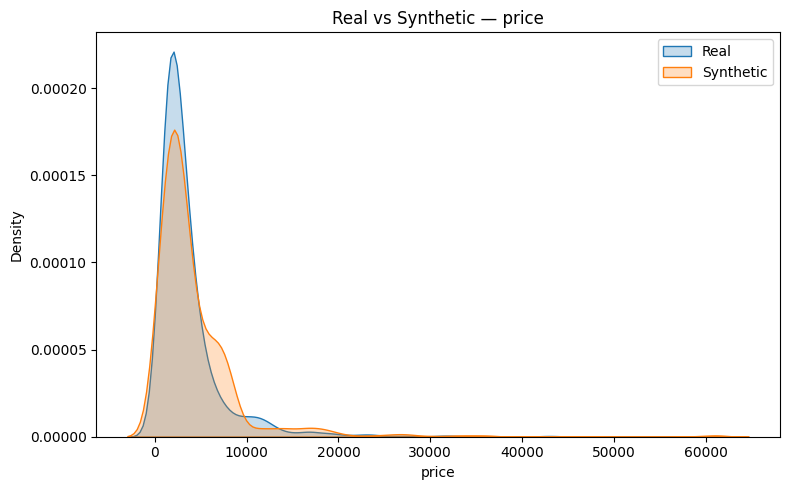

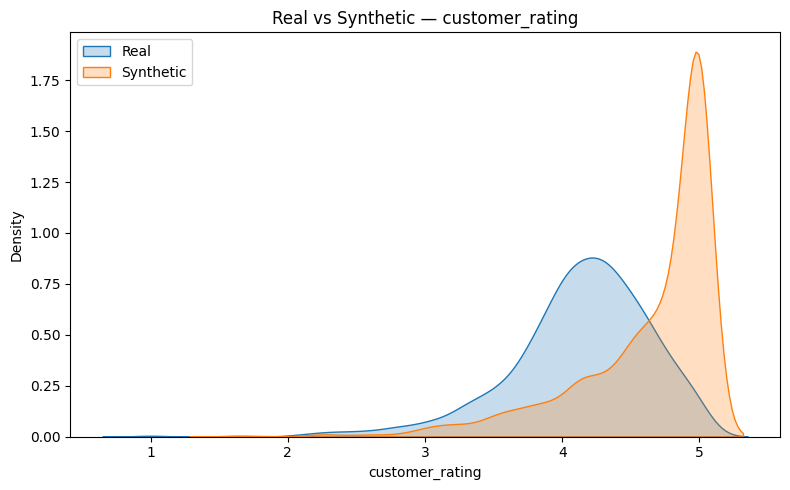

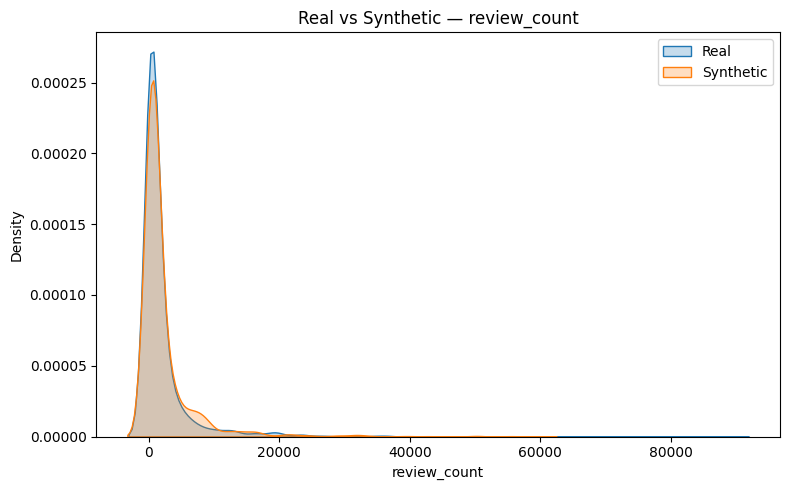

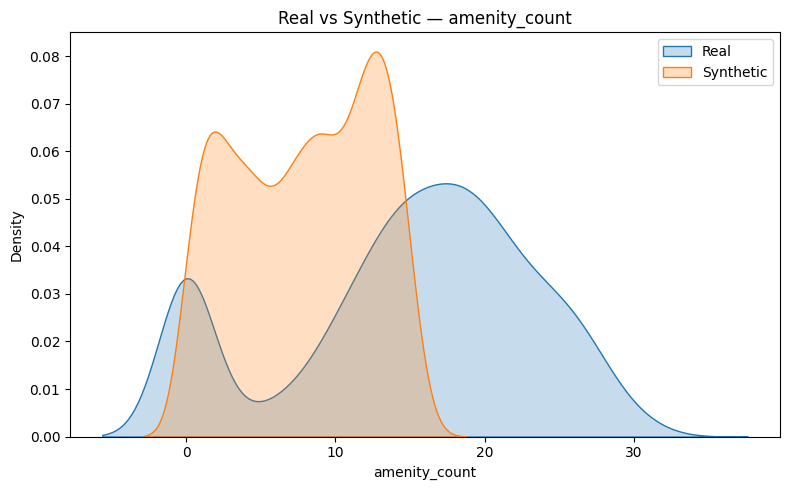

In [ ]:
# ============================================================
# CELL 27 — Distribution plots
# ============================================================

plot_cols = [
    "price",
    "customer_rating",
    "review_count",
    "amenity_count"
]

for col in plot_cols:
    plt.figure(figsize=(8, 5))

    sns.kdeplot(
        data=real,
        x=col,
        label="Real",
        fill=True,
        alpha=0.25
    )

    sns.kdeplot(
        data=synthetic,
        x=col,
        label="Synthetic",
        fill=True,
        alpha=0.25
    )

    plt.title(f"Real vs Synthetic — {col}")
    plt.xlabel(col)
    plt.ylabel("Density")
    plt.legend()
    plt.tight_layout()
    plt.show()

# 18. Boxplots for numerical comparison

# 19. Compare amenity prevalence

This is particularly important because the project is based on **hotel amenities**.

In [ ]:
# ============================================================
# CELL 29 — Amenity prevalence comparison
# ============================================================

amenity_results = []

for col in AMENITY_COLS:
    real_rate = real[col].mean() * 100
    syn_rate = synthetic[col].mean() * 100

    amenity_results.append({
        "amenity": col.replace("amenity_", ""),
        "real_percent": real_rate,
        "synthetic_percent": syn_rate,
        "absolute_difference": abs(real_rate - syn_rate)
    })

amenity_comparison = pd.DataFrame(
    amenity_results
).sort_values(
    "real_percent",
    ascending=False
)

display(
    amenity_comparison.round(2)
)

,amenity,real_percent,synthetic_percent,absolute_difference
0,count,1495.07,788.99,706.09
1,air_conditioning,77.39,78.42,1.03
2,room_service,72.17,75.03,2.86
3,full_service_laundry,68.37,71.67,3.30
15,parking,66.41,67.44,1.03
4,free_wi_fi,64.21,62.11,2.11
5,kid_friendly,53.71,51.61,2.10
6,restaurant,48.55,47.11,1.44
7,free_breakfast,46.41,37.58,8.83
8,free_parking,45.88,45.24,0.64


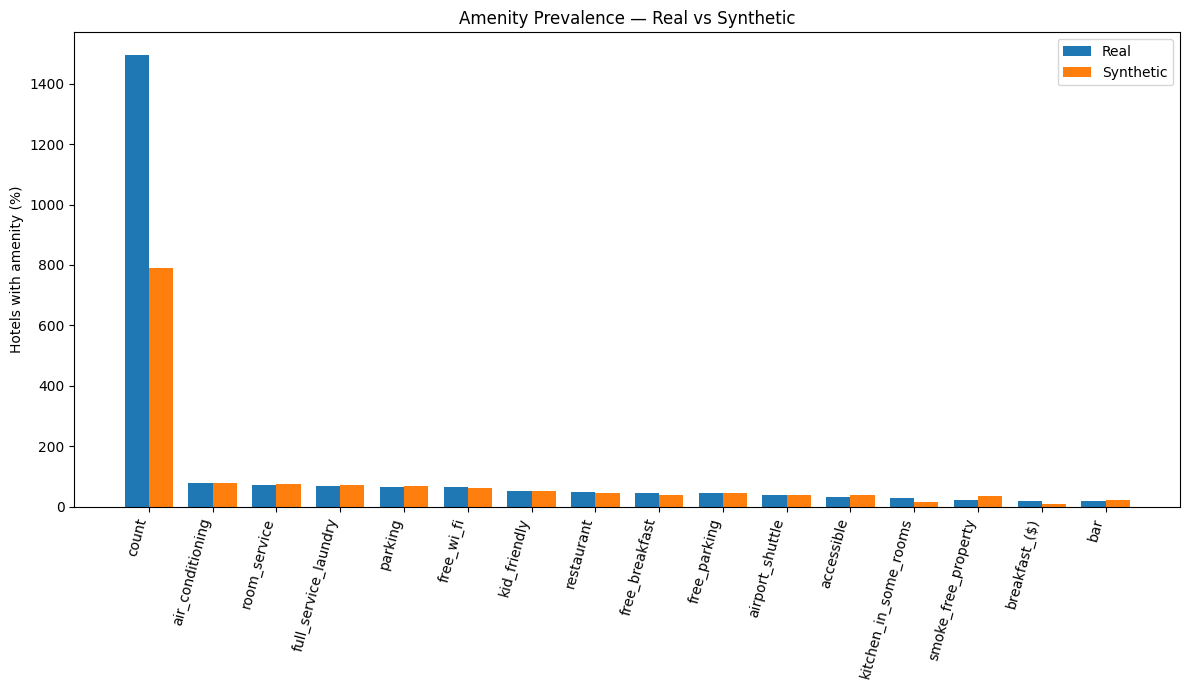

In [ ]:
# ============================================================
# CELL 30 — Amenity prevalence plot
# ============================================================

plot_df = amenity_comparison.copy()

plt.figure(figsize=(12, 7))

x = np.arange(len(plot_df))
width = 0.38

plt.bar(
    x - width/2,
    plot_df["real_percent"],
    width,
    label="Real"
)

plt.bar(
    x + width/2,
    plot_df["synthetic_percent"],
    width,
    label="Synthetic"
)

plt.xticks(
    x,
    plot_df["amenity"],
    rotation=75,
    ha="right"
)

plt.ylabel("Hotels with amenity (%)")
plt.title("Amenity Prevalence — Real vs Synthetic")
plt.legend()
plt.tight_layout()
plt.show()

# 20. Compare success distribution

Because `success` is your target variable, we need to make sure CTGAN did not produce an unrealistic success distribution.

,Real (%),Synthetic (%)
success,,
0,30.09,14.48
1,69.91,85.52


<Figure size 600x500 with 0 Axes>

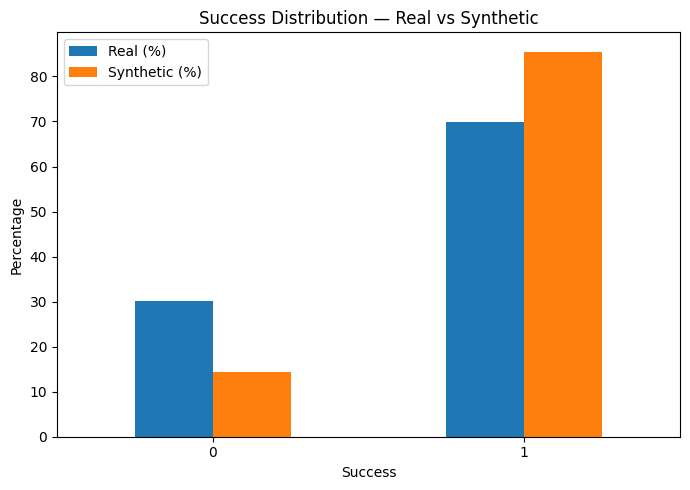

In [ ]:
# ============================================================
# CELL 31 — Success distribution
# ============================================================

success_comparison = pd.DataFrame({
    "Real (%)": real["success"].value_counts(normalize=True).sort_index() * 100,
    "Synthetic (%)": synthetic["success"].value_counts(normalize=True).sort_index() * 100
}).fillna(0)

display(success_comparison.round(2))

plt.figure(figsize=(6, 5))

success_plot = success_comparison.reset_index()
success_plot.columns = ["success", "Real (%)", "Synthetic (%)"]

success_plot.plot(
    x="success",
    y=["Real (%)", "Synthetic (%)"],
    kind="bar",
    figsize=(7, 5)
)

plt.title("Success Distribution — Real vs Synthetic")
plt.ylabel("Percentage")
plt.xlabel("Success")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 21. Compare amenity_count by success

This is useful for your later analysis because it checks whether the synthetic dataset preserves the relationship between the **number of amenities** and **hotel success**.

In [ ]:
# ============================================================
# CELL 32 — Amenity count vs success
# ============================================================

real_summary = (
    real.groupby("success")["amenity_count"]
    .agg(["mean", "median", "count"])
    .rename(columns={
        "mean": "real_mean",
        "median": "real_median",
        "count": "real_count"
    })
)

syn_summary = (
    synthetic.groupby("success")["amenity_count"]
    .agg(["mean", "median", "count"])
    .rename(columns={
        "mean": "synthetic_mean",
        "median": "synthetic_median",
        "count": "synthetic_count"
    })
)

relationship_comparison = pd.concat(
    [real_summary, syn_summary],
    axis=1
)

display(relationship_comparison.round(3))

,real_mean,real_median,real_count,synthetic_mean,synthetic_median,synthetic_count
success,,,,,,
0,13.089,14.0,507,6.050,6.0,418
1,15.752,17.0,1178,8.201,9.0,2469


# 22. Correlation comparison

This compares relationships among the most important numerical variables.

In [ ]:
# ============================================================
# CELL 33 — Correlation matrices
# ============================================================

CORR_COLS = [
    "price",
    "log_price",
    "customer_rating",
    "review_count",
    "amenity_count",
    "success"
]

real_corr = real[CORR_COLS].corr()
syn_corr = synthetic[CORR_COLS].corr()

print("Real correlation matrix")
display(real_corr.round(3))

print("Synthetic correlation matrix")
display(syn_corr.round(3))

print("Absolute correlation difference")
display((real_corr - syn_corr).abs().round(3))

Real correlation matrix


,price,log_price,customer_rating,review_count,amenity_count,success
price,1.000,0.829,0.182,0.540,0.297,0.193
log_price,0.829,1.000,0.221,0.489,0.360,0.253
customer_rating,0.182,0.221,1.000,0.135,0.112,0.766
review_count,0.540,0.489,0.135,1.000,0.339,0.155
amenity_count,0.297,0.360,0.112,0.339,1.000,0.147
success,0.193,0.253,0.766,0.155,0.147,1.000


Synthetic correlation matrix


,price,log_price,customer_rating,review_count,amenity_count,success
price,1.000,0.765,0.025,0.106,0.262,0.026
log_price,0.765,1.000,0.016,0.128,0.401,0.053
customer_rating,0.025,0.016,1.000,-0.027,0.068,0.006
review_count,0.106,0.128,-0.027,1.000,0.293,0.050
amenity_count,0.262,0.401,0.068,0.293,1.000,0.165
success,0.026,0.053,0.006,0.050,0.165,1.000


Absolute correlation difference


,price,log_price,customer_rating,review_count,amenity_count,success
price,0.000,0.064,0.157,0.434,0.035,0.167
log_price,0.064,0.000,0.205,0.361,0.042,0.200
customer_rating,0.157,0.205,0.000,0.162,0.044,0.760
review_count,0.434,0.361,0.162,0.000,0.045,0.105
amenity_count,0.035,0.042,0.044,0.045,0.000,0.018
success,0.167,0.200,0.760,0.105,0.018,0.000


# 23. Final quality summary

The following summary provides a compact report of:

- row counts
- exact duplicate count
- near-duplicate count
- numerical KS statistics
- amenity distribution differences
- success-rate difference

In [ ]:
# ============================================================
# CELL 34 — Final quality report
# ============================================================

real_success_rate = real["success"].mean() * 100
synthetic_success_rate = synthetic["success"].mean() * 100

quality_report = {
    "real_rows": len(real),
    "synthetic_rows": len(synthetic),
    "combined_rows": len(combined),
    "real_unique_hotels": real["hotel_id"].nunique(),
    "synthetic_unique_ids": synthetic["hotel_id"].nunique(),
    "exact_duplicate_synthetic_records": int(exact_duplicate_count),
    "near_duplicate_synthetic_records_removed": int((~KEEP_SYNTHETIC).sum()),
    "real_success_percent": round(real_success_rate, 2),
    "synthetic_success_percent": round(synthetic_success_rate, 2),
    "success_percent_difference": round(
        abs(real_success_rate - synthetic_success_rate),
        2
    ),
    "mean_amenity_difference": round(
        amenity_comparison["absolute_difference"].mean(),
        2
    ),
    "max_amenity_difference": round(
        amenity_comparison["absolute_difference"].max(),
        2
    ),
    "mean_numeric_KS": round(
        numeric_comparison["KS_statistic"].mean(),
        4
    )
}

quality_report_df = pd.DataFrame(
    quality_report.items(),
    columns=["metric", "value"]
)

display(quality_report_df)

,metric,value
0,real_rows,1685.0000
1,synthetic_rows,2887.0000
2,combined_rows,4572.0000
3,real_unique_hotels,1685.0000
4,synthetic_unique_ids,2887.0000
5,exact_duplicate_synthetic_records,0.0000
6,near_duplicate_synthetic_records_removed,113.0000
7,real_success_percent,69.9100
8,synthetic_success_percent,85.5200
9,success_percent_difference,15.6100


# 24. Download all generated files

The notebook creates:

- `real_hotels.csv`
- `synthetic_hotels.csv`
- `combined_real_synthetic_hotels.csv`

All files are stored in the `synthetic_hotel_outputs` folder.

In [ ]:
# ============================================================
# CELL 35 — Download CSV files
# ============================================================

from google.colab import files
import shutil

# Create a ZIP containing all three CSVs
zip_path = shutil.make_archive(
    "synthetic_hotel_outputs",
    "zip",
    OUTPUT_DIR
)

print("ZIP created:", zip_path)

files.download(zip_path)

ZIP created: /content/synthetic_hotel_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Interpretation guide

Use the validation results rather than claiming that the synthetic data are automatically "proof" of correctness.

A reasonable synthetic-data result should show:

- similar price distributions
- similar rating distributions
- similar amenity prevalence
- similar success rate
- similar amenity-count distribution
- similar relationships between important variables
- very few exact/near duplicates

For your report, describe this as **distributional validation**.

Example wording:

> "Synthetic hotel records were generated using CTGAN trained on the hotel-level dataset. The synthetic data were evaluated against the real data using numerical distribution comparisons, categorical prevalence, amenity prevalence, correlation analysis, and duplicate/near-duplicate checks. Derived variables such as amenity count, log-transformed price, and PCA components were recalculated from the generated features to maintain internal consistency."

Do **not** claim that synthetic records represent actual hotels or that statistical similarity proves the synthetic data are identical to the real population.